In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
from PIL import Image
from tqdm import tqdm
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [ ]:
import opendatasets as od 

In [ ]:
od.download(
    "https://www.kaggle.com/datasets/hayder17/breast-cancer-detection /data")

In [6]:
base_path = "C:\\Users\\Dell\\Desktop\\Nowy folder\\PJATK\\III SEMESTR\\ZUM\\breast-cancer-detection"

#### Loading dataset 

In [42]:
split = ["train", "test", "valid"]
classes = ["0", "1"]

def load_datasets(split):
    paths = []
    labels = []
    for label in classes:
        folder = os.path.join(base_path, split, label)
        for img in os.listdir(folder):
            paths.append(os.path.join(folder, img))
            labels.append(label)
    return pd.DataFrame({"path": paths, "label": labels})   

In [43]:
df_train = load_datasets("train")
df_test = load_datasets("test")
df_valid = load_datasets("valid")

#### Distribution

In [18]:
dist = pd.crosstab(df["split"],df["class"])
dist_p = dist.div(dist.sum(axis=1), axis=0)*100
dist_p.round(2)

class,0,1
split,,
test,61.90,38.10
train,66.15,33.85
valid,66.37,33.63


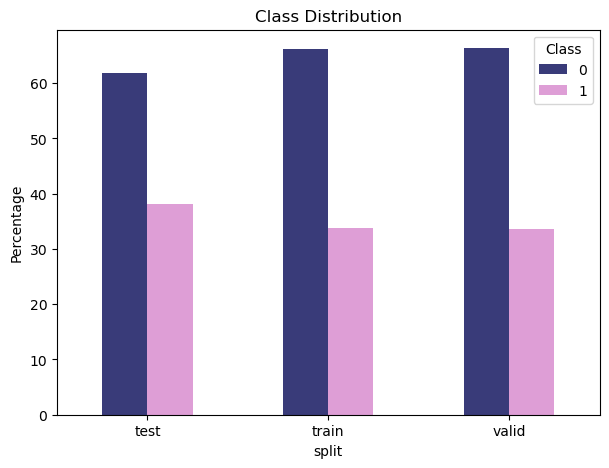

In [33]:
dist_p.plot(kind="bar", figsize=(7,5), colormap='tab20b')
plt.ylabel("Percentage")
plt.title("Class Distribution")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.show()

#### Size 

In [52]:
def get_size(path):
    img = Image.open(path)
    return img.size

df_train["size"] = df_train["path"].apply(get_size)
df_test["size"] = df_test["path"].apply(get_size)
df_valid["size"] = df_valid["path"].apply(get_size)

In [54]:
print(df_train["size"].unique())
print(df_test["size"].unique())
print(df_valid["size"].unique())

[(640, 640)]
[(640, 640)]
[(640, 640)]


#### Images - examples

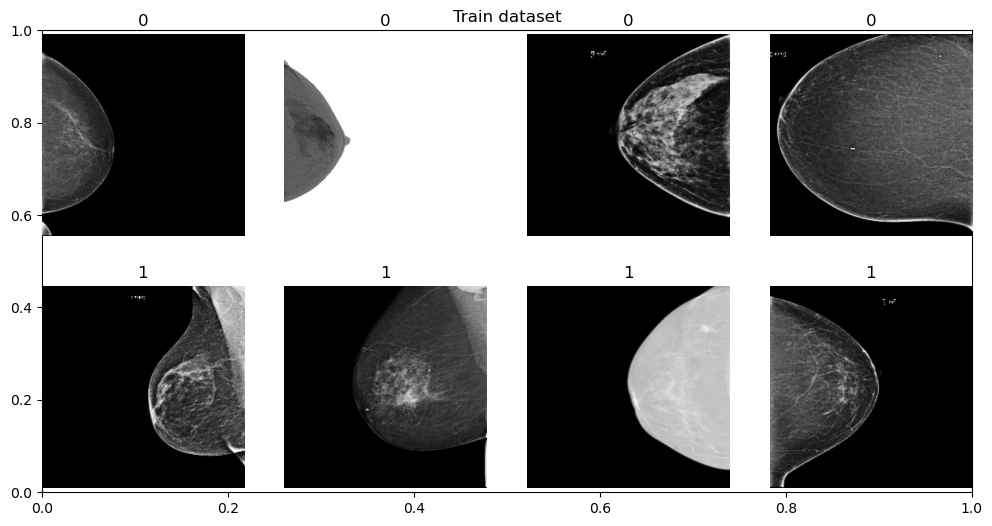

In [70]:
plt.figure(figsize=(12,6))
plt.title("Train dataset")
subplot_nr = 1
for label in classes:
    images = df_train[df_train["label"] == label].sample(4)["path"]
    for path in images:
        img = Image.open(path).convert("L")
        plt.subplot(2, 4, subplot_nr)
        plt.imshow(img, cmap="gray")
        plt.title(label)
        plt.axis("off")
        subplot_nr += 1
plt.show()

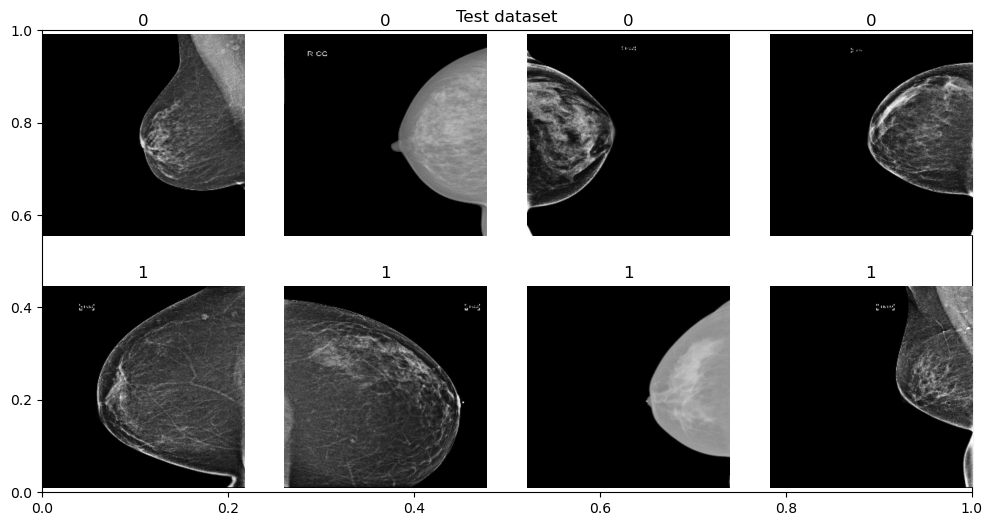

In [73]:
plt.figure(figsize=(12,6))
plt.title("Test dataset")
subplot_nr = 1
for label in classes:
    images = df_test[df_test["label"] == label].sample(4)["path"]
    for path in images:
        img = Image.open(path).convert("L")
        plt.subplot(2, 4, subplot_nr)
        plt.imshow(img, cmap="gray")
        plt.title(label)
        plt.axis("off")
        subplot_nr += 1
plt.show()

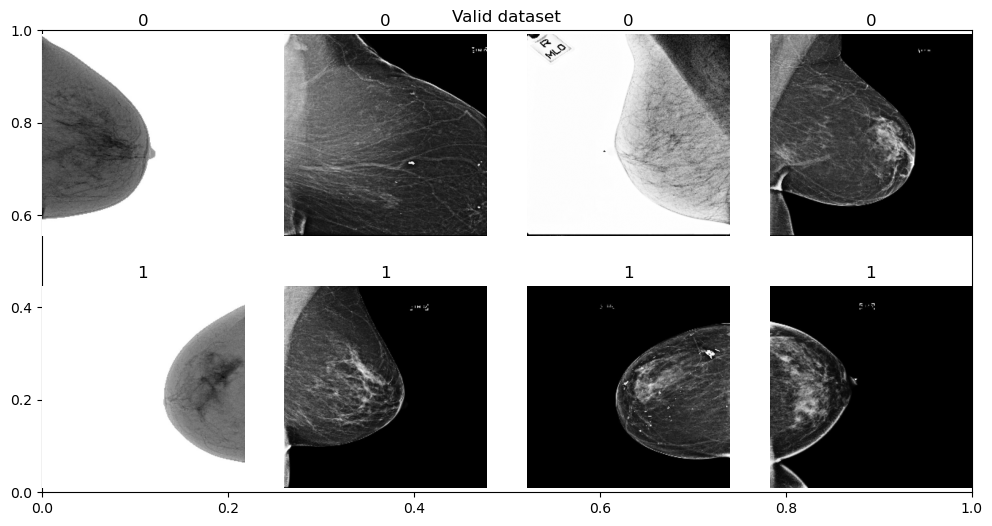

In [74]:
plt.figure(figsize=(12,6))
plt.title("Valid dataset")
subplot_nr = 1
for label in classes:
    images = df_valid[df_valid["label"] == label].sample(4)["path"]
    for path in images:
        img = Image.open(path).convert("L")
        plt.subplot(2, 4, subplot_nr)
        plt.imshow(img, cmap="gray")
        plt.title(label)
        plt.axis("off")
        subplot_nr += 1
plt.show()